## Table of Contents

<div class="alert alert-block alert-info" style="margin-top: 20px">

1.  [Import Libraries](#1)<br>
2.  [Importing Data](#2)<br>
3.  [Line Plot](#3) <br>
4.  [Scatter Plot](#4) <br>
5.  [Bar Plot](#5) <br>
6.  [Histogram](#6) <br>
7.  [Pie](#7) <br>
8.  [Subplotting](#8) <br>
</div>


# Import Libraries<a id="1"></a>


Import the `matplotlib` library.

In [1]:
# Import Modul Utama
# Import Matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np  # berguna untuk banyak komputasi ilmiah di Python
import pandas as pd  # pustaka struktur data utama

In [2]:
# Periksa versi Matplotlib terbaru.
print("Matplotlib version:", mpl.__version__)

Matplotlib version: 3.11.2


## Importing Data<a id="2"></a>
Dataset: Imigrasi ke Kanada dari tahun 1980 hingga 2013 - [International migration flows to and from selected countries - The 2015 revision](https://www.un.org/development/desa/pd/data/international-migration-flows) dari website United Nation's 

Dalam lab ini, data yang digunakan akn berfokus pada Imigrasi Kanada dan menggunakan **dataset yang sudah dibersihkan** dan dapat diunduh dari <a href="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Canada.csv">disini</a>.<br><br>
Anda dapat merujuk ke lab tentang pra-pemrosesan data di mana dataset ini dibersihkan untuk penyegaran cepat keterampilan Pandas, melalui [Data pre-processing with Pandas](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/labs/june2023_updates/Module%201/DV0101EN-Exercise-Dataset-Preprocessing-Exploring-with-Pandas.ipynb)


In [3]:
df_canada = pd.read_csv("../../data/raw/Canada.csv")
df_canada.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
1,Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,...,1223,856,702,560,716,561,539,620,603,15699
2,Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
3,American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
4,Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,...,0,1,1,0,0,0,0,1,1,15


Mari kita cari tahu berapa banyak entri yang ada dalam dataset kita.

In [4]:
print(df_canada.shape)

(195, 39)


Tetapkan nama negara sebagai indeks - berguna untuk mencari negara dengan cepat menggunakan metode `.loc.`

In [5]:
df_canada.set_index("Country", inplace=True)

In [6]:
df_canada.head()

,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,1986,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
Country,,,,,,,,,,,,,,,,,,,,,
Afghanistan,Asia,Southern Asia,Developing regions,16,39,39,47,71,340,496,...,3436,3009,2652,2111,1746,1758,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,0,0,0,0,0,1,...,1223,856,702,560,716,561,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,67,71,69,63,44,69,...,3626,4807,3623,4005,5393,4752,4325,3774,4331,69439
American Samoa,Oceania,Polynesia,Developing regions,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,6
Andorra,Europe,Southern Europe,Developed regions,0,0,0,0,0,0,2,...,0,1,1,0,0,0,0,1,1,15


Perhatikan bahwa nama-nama negara sekarang berfungsi sebagai indeks.

In [7]:
print("data dimensions:", df_canada.shape)

data dimensions: (195, 38)


In [8]:
# Terakhir, mari kita buat daftar tahun dari 1980 - 2013
# Ini akan berguna saat kita mulai memplot data

years = list(map(str, range(1980, 2014)))
years

['1980',
 '1981',
 '1982',
 '1983',
 '1984',
 '1985',
 '1986',
 '1987',
 '1988',
 '1989',
 '1990',
 '1991',
 '1992',
 '1993',
 '1994',
 '1995',
 '1996',
 '1997',
 '1998',
 '1999',
 '2000',
 '2001',
 '2002',
 '2003',
 '2004',
 '2005',
 '2006',
 '2007',
 '2008',
 '2009',
 '2010',
 '2011',
 '2012',
 '2013']

# Line Plot<a id="3"></a>


Line plot atau grafik garis menampilkan hubungan antara dua variabel kontinu dalam interval kontinu, menunjukkan tren atau pola data.<br><br>Mari kita buat grafik garis untuk memvisualisasikan tren imigran (ke Kanada) selama tahun 1980 hingga 2013.<br>Kita membutuhkan total imigran per tahun,<br><br>Kita akan membuat dataframe baru hanya untuk kolom yang berisi tahun,<br>kemudian, kita akan menerapkan fungsi sum() pada dataframe tersebut.<br><br>Anda dapat membuat grafik garis langsung pada **axes** dengan memanggil fungsi plot **plot()**.

In [9]:
# Membuat dataframe hanya dengan kolom tahun dari tahun 1980 - 2013.
df_line = df_canada[years]

# Menerapkan penjumlahan (sum()) untuk mendapatkan total imigran per tahun.
total_immigrants = df_line.sum()
total_immigrants

1980     99137
1981    110563
1982    104271
1983     75550
1984     73417
1985     69978
1986     86048
1987    134771
1988    139306
1989    164432
1990    188054
1991    207509
1992    221687
1993    222049
1994    193665
1995    187712
1996    200085
1997    192885
1998    160727
1999    179818
2000    216712
2001    242643
2002    223111
2003    217297
2004    232083
2005    257457
2006    247057
2007    232405
2008    243047
2009    248768
2010    276956
2011    246194
2012    256222
2013    257537
dtype: int64

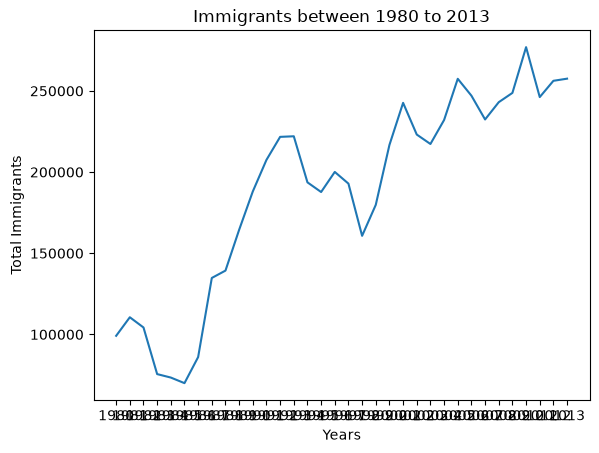

In [10]:
# Membuat gambar dan sumbu
fig, ax = plt.subplots()

# Menggambar garis
ax.plot(total_immigrants)

# Mengatur Judul
ax.set_title("Immigrants between 1980 to 2013")

# Mengatur Label
ax.set_xlabel("Years")
ax.set_ylabel("Total Immigrants")

# Menampilkan plot
plt.show()

#### Fungsi plot mengisi sumbu x dengan nilai indeks (tahun), dan sumbu y dengan nilai kolom (populasi). <br>Namun, perhatikan bagaimana tahun tidak ditampilkan karena bertipe string.<br> <br>Oleh karena itu, mari kita ubah tipe nilai indeks menjadi integer untuk pembuatan plot.

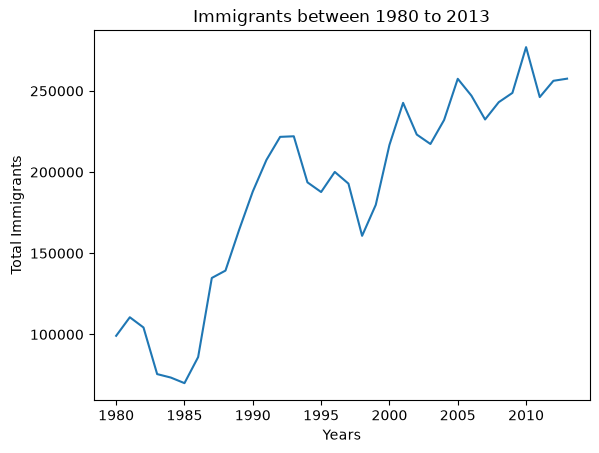

In [11]:
# Membuat gambar dan sumbu
fig, ax = plt.subplots()

# Mengubah tipe indeks menjadi bilangan bulat.
total_immigrants.index = total_immigrants.index.map(int)

# Menggambar garis
ax.plot(total_immigrants)

# Mengatur Judul
ax.set_title("Immigrants between 1980 to 2013")

# Mengatur Label
ax.set_xlabel("Years")
ax.set_ylabel("Total Immigrants")

# Menampilkan plot
plt.show()

#### Sekarang mari kita sesuaikan tampilan plot di atas

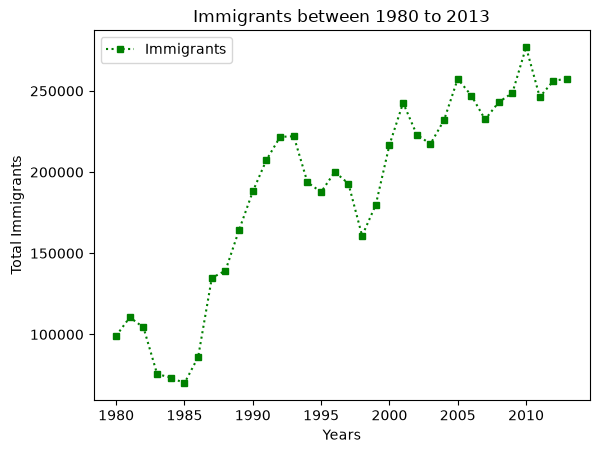

In [12]:
# Membuat gambar dan sumbu
fig, ax = plt.subplots()

# Mengubah tipe indeks menjadi bilangan bulat.
total_immigrants.index = total_immigrants.index.map(int)

# Menyesuaikan tampilan Plot
ax.plot(
    total_immigrants,
    marker="s",  # Termasuk penanda dalam bentuk persegi
    markersize=5,  # Mengatur ukuran penanda
    color="green",  # Mengubah warna garis
    linestyle="dotted",
)  # Mengubah gaya garis menjadi garis putus-putus

# Mengatur Judul
ax.set_title("Immigrants between 1980 to 2013")

# Mengatur Label
ax.set_xlabel("Years")
ax.set_ylabel("Total Immigrants")
ax.legend(["Immigrants"])

# Menampilkan plot
plt.show()

#### Mari kita sertakan grid latar belakang, legenda, dan coba ubah batas pada sumbu.

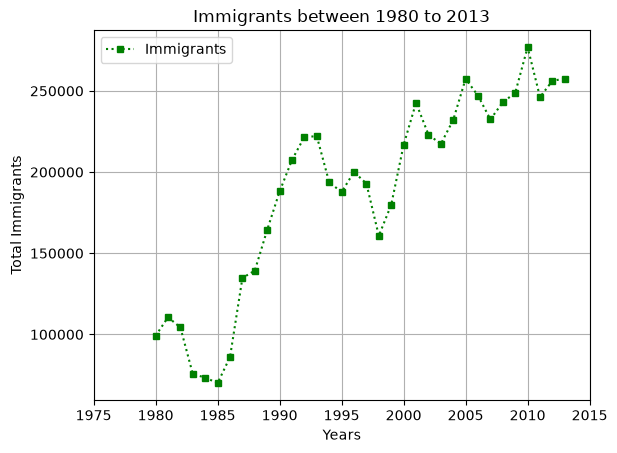

In [13]:
fig, ax = plt.subplots()

total_immigrants.index = total_immigrants.index.map(int)

ax.plot(total_immigrants, marker="s", markersize=5, color="green", linestyle="dotted")

ax.set_title("Immigrants between 1980 to 2013")
ax.set_xlabel("Years")
ax.set_ylabel("Total Immigrants")

# Ubah batas tahun pada sumbu-x
plt.xlim(1975, 2015)
# Menambahkan grid pada latar belakang
plt.grid(True)
# Menambahkan legend dari penanda
plt.legend(["Immigrants"])

# Tampilkan plot
plt.show()

Mari kita mulai dengan studi kasus:

Pada tahun 2010, Haiti mengalami gempa bumi dahsyat berkekuatan 7,0 skala Richter. Gempa tersebut menyebabkan kerusakan luas dan hilangnya nyawa, dan sekitar tiga juta orang terkena dampak bencana alam ini. Sebagai bagian dari upaya kemanusiaan Kanada, Pemerintah Kanada meningkatkan upayanya dalam menerima pengungsi dari Haiti. Kita dapat dengan cepat memvisualisasikan upaya ini menggunakan grafik garis:

### Pertanyaan: Gambarkan grafik garis imigrasi dari Haiti

Anda akan diminta untuk membuat dataframe di mana nama 'Country' sama dengan 'Haiti' dan tahun dari 1980 - 2013.<br> Anda juga akan diminta untuk mentranspos dataframe baru tersebut menjadi series untuk pembuatan plot.<br> Anda mungkin juga perlu mengubah tipe indeks series menjadi integer agar plot terlihat lebih baik.<br> Kemudian buat fig dan ax dan panggil fungsi plot() pada data tersebut.

In [14]:
# membuat dataframe dari data imigran negara Haiti
df_canada.reset_index(inplace=True)
haiti = df_canada[df_canada["Country"] == "Haiti"]
haiti.head()

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
75,Haiti,Latin America and the Caribbean,Caribbean,Developing regions,1666,3692,3498,2860,1418,1321,...,1682,1619,1598,2491,2080,4744,6503,5868,4152,84813


In [15]:
# Membuat data Haiti hanya dengan kolom tahun dari 1980 - 2013
# dan mentransposisikannya untuk mendapatkan hasil berupa deret
haiti = haiti[years].T
haiti.head()

,75
1980,1666
1981,3692
1982,3498
1983,2860
1984,1418


In [16]:
# Ubah nama kolom
haiti.columns = ["Haiti"]
haiti.head()

,Haiti
1980,1666
1981,3692
1982,3498
1983,2860
1984,1418


In [17]:
# ubah indeks dataframe menjadi integer untuk mempermudah membuat plot
haiti.index = haiti.index.map(int)

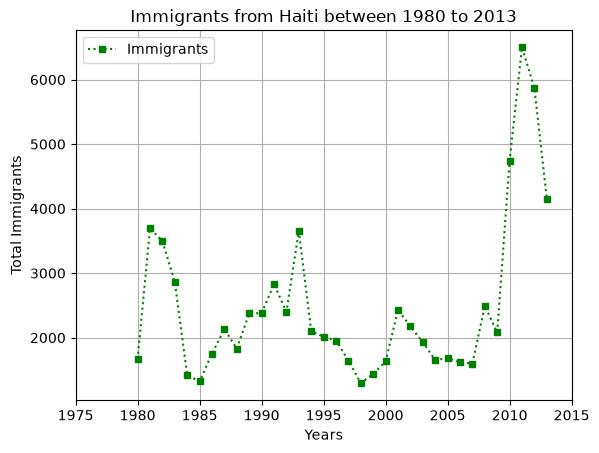

In [18]:
# buat fig dan axes
fig, ax = plt.subplots()

# buat line plot
ax.plot(haiti, marker="s", markersize=5, color="green", linestyle="dotted")

# buat judul plot
ax.set_title("Immigrants from Haiti between 1980 to 2013")
# buat label
ax.set_xlabel("Years")
ax.set_ylabel("Total Immigrants")
# buat batas x-axes baru
ax.set_xlim(1975, 2015)
# tambahkan grid
ax.grid(True)
# tambahkan legend
ax.legend(["Immigrants"])

# tampilkan plot
plt.show()

#### Kita dapat dengan jelas melihat bagaimana jumlah imigran dari Haiti melonjak tajam sejak tahun 2010 seiring dengan meningkatnya upaya Kanada untuk menerima pengungsi dari Haiti. <br>Mari kita beri anotasi pada lonjakan ini dalam grafik dengan menggunakan metode *ax.annotate()*.

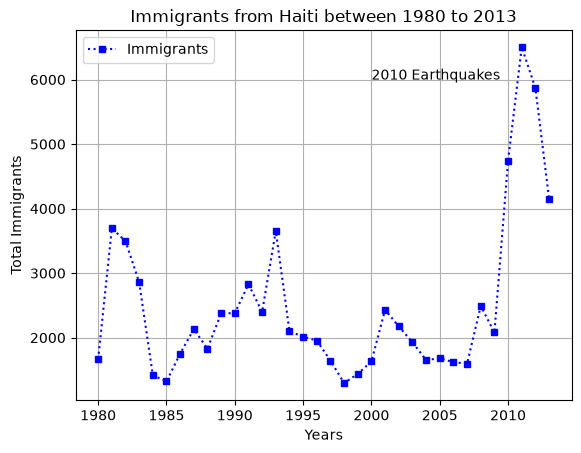

In [19]:
fig, ax = plt.subplots()

ax.plot(haiti, marker="s", markersize=5, color="blue", linestyle="dotted")

ax.set_title("Immigrants from Haiti between 1980 to 2013")
ax.set_xlabel("Years")
ax.set_ylabel("Total Immigrants")

ax.grid(True)
ax.legend(["Immigrants"])
ax.set_xticks(list(range(1980, 2015, 5)))

ax.annotate("2010 Earthquakes", xy=(2000, 6000))

plt.show()

---

# Scatter Plot<a id="4"></a>


Diagram sebar (scatter plot) memvisualisasikan hubungan antara dua variabel kontinu, menampilkan titik data individual sebagai titik pada bidang dua dimensi, memungkinkan pemeriksaan pola, klaster, dan korelasi.<br><br>Mari kita buat *Diagram Sebar* untuk memvisualisasikan tren imigran (ke Kanada) selama tahun 1980 hingga 2013.<br>Kita membutuhkan Total imigran per tahun,<br><br>Kita akan membuat dataframe baru hanya untuk kolom yang berisi tahun<br> kemudian, kita akan menerapkan fungsi sum() pada dataframe<br><br>Anda dapat membuat diagram sebar langsung pada **ax** dengan memanggil fungsi plot **scatter()**

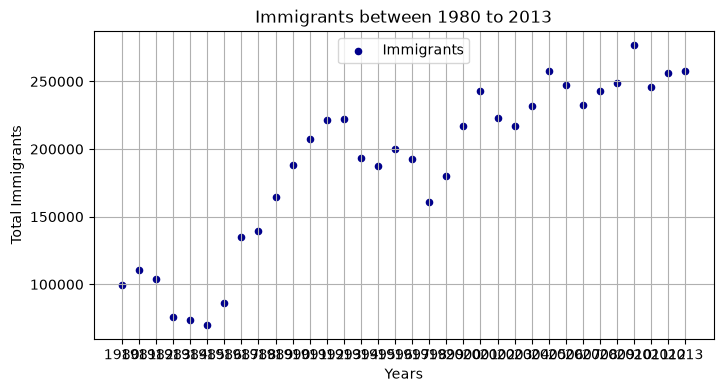

In [20]:
# Buat figure dan axes
fig, ax = plt.subplots(figsize=(8, 4))

# Buat scatter plot
ax.scatter(years, total_immigrants,
          marker="o", # tambahkan penanda lingkaran (o)
          s=20, # ukuran dari penanda
          color="darkblue" # warna penanda
          )

# Tambahkan judul
ax.set_title("Immigrants between 1980 to 2013")
# Tambahkan label
ax.set_xlabel("Years")
ax.set_ylabel("Total Immigrants")
# Tambahkan grid
ax.grid(True)
# Tambahkan legend di tengah atas
ax.legend(["Immigrants"], loc="upper center")

# Tampilkan plot
plt.show()

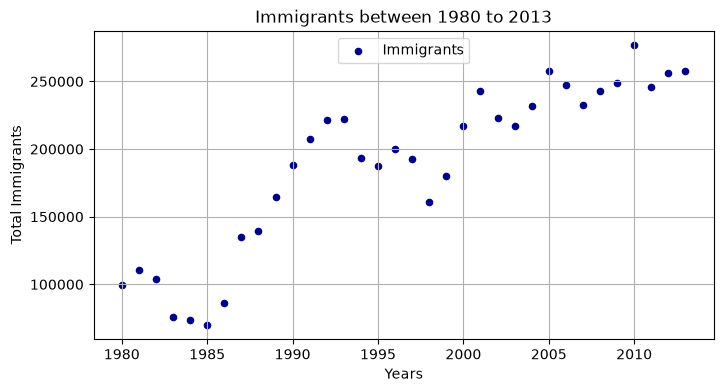

In [21]:
# Versi plot yang lebih baik
# Buat figure dan axes
fig, ax = plt.subplots(figsize=(8, 4))

# Ubah tahun pada x-axes menjadi int
total_immigrants.index = total_immigrants.index.map(int)

# Buat scatter plot
ax.scatter(total_immigrants.index, total_immigrants, marker="o", s=20,
          color="darkblue")
# Tambahkan judul
ax.set_title("Immigrants between 1980 to 2013")
# Tambahkan label
ax.set_xlabel("Years")
ax.set_ylabel("Total Immigrants")
# Tambahkan grid
ax.grid(True)
# Tambahkan legend di tengah atas
ax.legend(["Immigrants"], loc="upper center")

# Tampilkan plot
plt.show()

### Refer to the [matplotlib documentation](https://matplotlib.org/stable/api/markers_api.html) and change the marker and its size, color in the above code to see the difference in the appearance of the plot


---

# Bar Plot<a id="5"></a>


Diagram batang merepresentasikan data kategorikal dengan batang persegi panjang, di mana tinggi setiap batang sesuai dengan nilai kategori tertentu, sehingga cocok untuk membandingkan nilai di berbagai kategori.<br><br>Mari kita buat diagram batang untuk memvisualisasikan 5 negara teratas yang paling banyak menyumbang imigran ke Kanada dari tahun 1980 hingga 2013.
<br><br>Terapkan fungsi sort_values ​​pada kolom 'Total' dari data kita.<br><br>Kita akan membuat dataframe baru hanya untuk kolom yang berisi tahun.<br>Kemudian, kita akan menerapkan sum() pada dataframe dan dapat membuat dataframe terpisah untuk lima negara teratas.<br><br>Anda dapat menggunakan nama-nama negara tersebut untuk memberi label pada setiap batang pada diagram.

In [22]:
# Urutkan dataframe berdasarkan Total dalam urutan menurun (descending)
df_canada.sort_values("Total", ascending=False, axis=0, inplace=True)

In [23]:
# Ambil 5 negara teratas menggunakan head() function
df_top_5 = df_canada.head()
df_top_5

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
79,India,Asia,Southern Asia,Developing regions,8880,8670,8147,7338,5704,4211,...,36210,33848,28742,28261,29456,34235,27509,30933,33087,691904
36,China,Asia,Eastern Asia,Developing regions,5123,6682,3308,1863,1527,1816,...,42584,33518,27642,30037,29622,30391,28502,33024,34129,659962
183,United Kingdom of Great Britain and Northern I...,Europe,Northern Europe,Developed regions,22045,24796,20620,10015,10170,9564,...,7258,7140,8216,8979,8876,8724,6204,6195,5827,551500
136,Philippines,Asia,South-Eastern Asia,Developing regions,6051,5921,5249,4562,3801,3150,...,18139,18400,19837,24887,28573,38617,36765,34315,29544,511391
130,Pakistan,Asia,Southern Asia,Developing regions,978,972,1201,900,668,514,...,14314,13127,10124,8994,7217,6811,7468,11227,12603,241600


In [24]:
# Atur ulang nomor indeksnya
df_bar_5 = df_top_5.reset_index()

In [25]:
df_bar_5.drop(columns="index")

,Country,Continent,Region,DevName,1980,1981,1982,1983,1984,1985,...,2005,2006,2007,2008,2009,2010,2011,2012,2013,Total
0,India,Asia,Southern Asia,Developing regions,8880,8670,8147,7338,5704,4211,...,36210,33848,28742,28261,29456,34235,27509,30933,33087,691904
1,China,Asia,Eastern Asia,Developing regions,5123,6682,3308,1863,1527,1816,...,42584,33518,27642,30037,29622,30391,28502,33024,34129,659962
2,United Kingdom of Great Britain and Northern I...,Europe,Northern Europe,Developed regions,22045,24796,20620,10015,10170,9564,...,7258,7140,8216,8979,8876,8724,6204,6195,5827,551500
3,Philippines,Asia,South-Eastern Asia,Developing regions,6051,5921,5249,4562,3801,3150,...,18139,18400,19837,24887,28573,38617,36765,34315,29544,511391
4,Pakistan,Asia,Southern Asia,Developing regions,978,972,1201,900,668,514,...,14314,13127,10124,8994,7217,6811,7468,11227,12603,241600


In [26]:
# Membuat daftar nama 5 negara teratas
label_top5 = list(df_bar_5.Country)
label_top5

['India',
 'China',
 'United Kingdom of Great Britain and Northern Ireland',
 'Philippines',
 'Pakistan']

##### Nama ketiga terlalu panjang untuk muat di sumbu x sebagai label. Mari kita perbaiki ini menggunakan pengindeksan.

In [27]:
# Ubah nama negara UK yang terlalu panjang
label_top5[2] = "UK"
label_top5

['India', 'China', 'UK', 'Philippines', 'Pakistan']

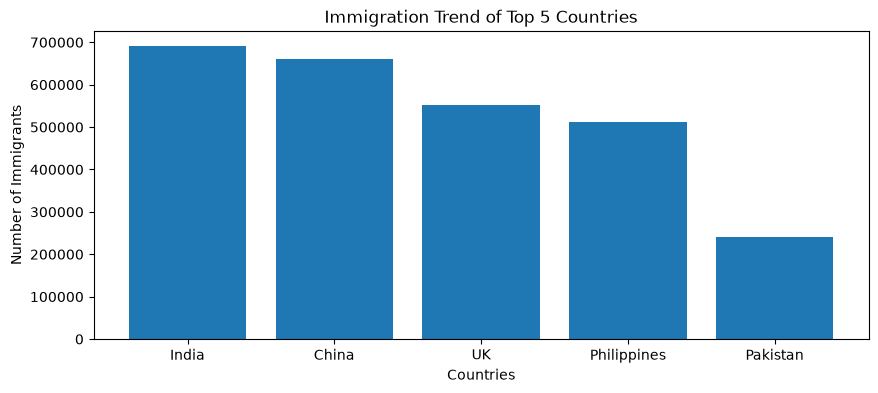

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))

# Buat bar plot
ax.bar(label_top5, df_bar_5["Total"], label=label_top5)
# Tambahkan judul
ax.set_title("Immigration Trend of Top 5 Countries")
# Tambahkan label
ax.set_xlabel("Countries")
ax.set_ylabel("Number of Immigrants")

#Tampilkan plot
plt.show()

### Pertanyaan: Buatlah diagram batang dari 5 negara yang memberikan kontribusi **paling sedikit** terhadap imigrasi ke Kanada **dari** tahun 1980 hingga 2013.

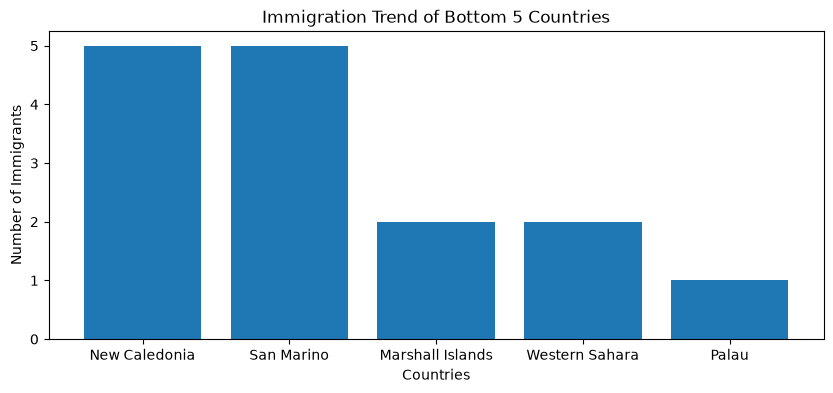

In [29]:
# Ambil daftar 5 negara dengan kontribusi paling sedikit
df_least5 = df_canada.tail()

# Atur ulang nilai indeksnya
df_least5.reset_index(inplace=True)

# Buang indeks lama
df_least5.drop(columns="index")

# Buat label dengan mengambil nama negaranya saja
label_least5 = list(df_least5.Country)

# Buat figure dan axes
fig, ax = plt.subplots(figsize=(10, 4))

# Buat bar plot
ax.bar(label_least5, df_least5["Total"], label=label_least5)
ax.set_title("Immigration Trend of Bottom 5 Countries")
ax.set_xlabel("Countries")
ax.set_ylabel("Number of Immigrants")
plt.show()

---

# Histogram<a id="6"></a>


Histogram adalah cara untuk merepresentasikan distribusi *frekuensi* dari dataset numerik. Cara kerjanya adalah membagi sumbu x menjadi *bin*, menetapkan setiap titik data dalam dataset kita ke dalam sebuah bin, dan kemudian menghitung jumlah titik data yang telah ditetapkan ke setiap bin. Jadi sumbu y adalah frekuensi atau jumlah titik data di setiap bin. Perhatikan bahwa kita dapat mengubah ukuran bin dan biasanya perlu disesuaikan agar distribusi ditampilkan dengan baik.
<br><br>Mari kita cari tahu distribusi frekuensi jumlah (populasi) imigran baru dari berbagai negara ke Kanada pada tahun 2013?<br>

In [30]:
# Cari daftar imigran pada tahun 2013, lalu jumlahlak
df_country = df_canada.groupby("Country")["2013"].sum().reset_index()
df_country.head()

,Country,2013
0,Afghanistan,2004
1,Albania,603
2,Algeria,4331
3,American Samoa,0
4,Andorra,1


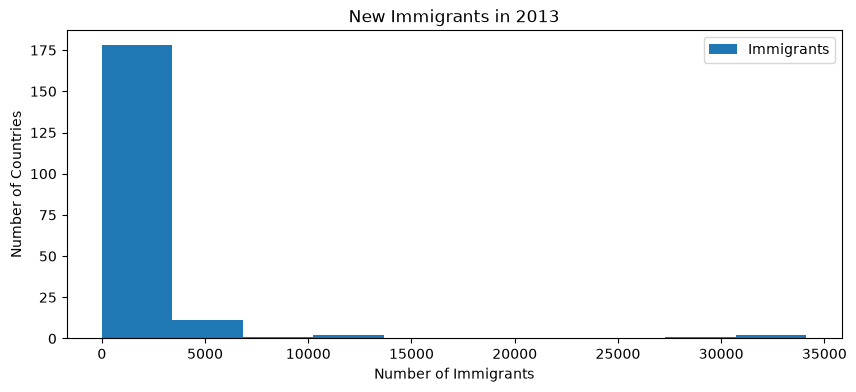

In [31]:
# Buat figure dan axes
fig, ax = plt.subplots(figsize=(10, 4))

# Buat histogram
ax.hist(df_country["2013"])
ax.set_title("New Immigrants in 2013")
ax.set_xlabel("Number of Immigrants")
ax.set_ylabel("Number of Countries")
ax.legend(["Immigrants"])

plt.show()

Plot kita tidak sesuai dengan batang<br>Secara default, metode `histogram` membagi dataset menjadi 10 bin. Gambar di bawah ini merangkum rentang bin dan distribusi frekuensi imigrasi pada tahun 2013<br> Fungsi `hist` mengembalikan daftar array dengan 1. jumlah dan 2. bin. Kita dapat mengambilnya menggunakan fungsi unpacking<br> dan selanjutnya menggunakan bin sebagai tanda x

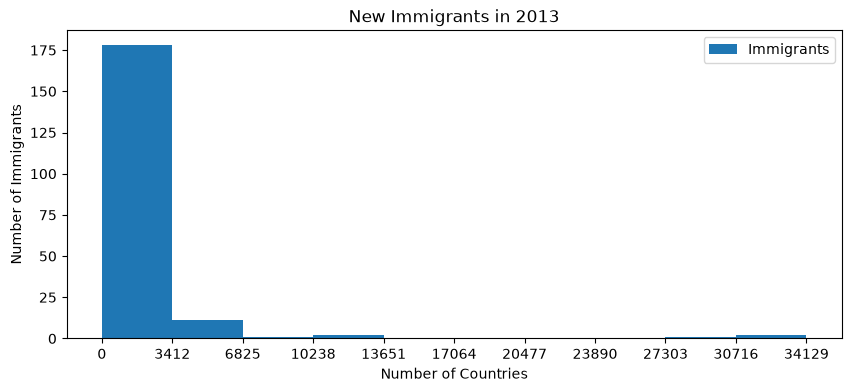

In [32]:
# Buat plot histogram
fig, ax = plt.subplots(figsize=(10, 4))
count = ax.hist(df_country["2013"])

# Anda dapat memeriksa array di count dengan pengindeksan count[0] untuk count, count[1] untuk bin
ax.set_title("New Immigrants in 2013")
ax.set_ylabel("Number of Immigrants")
ax.set_xlabel("Number of Countries")
ax.set_xticks(list(map(int, count[1])))
ax.legend(["Immigrants"])

plt.show()

In [33]:
print(count)

(array([178.,  11.,   1.,   2.,   0.,   0.,   0.,   0.,   1.,   2.]), array([    0. ,  3412.9,  6825.8, 10238.7, 13651.6, 17064.5, 20477.4,
       23890.3, 27303.2, 30716.1, 34129. ]), <BarContainer object of 10 artists>)


#### Kita juga dapat membuat beberapa histogram pada grafik yang sama. Misalnya, mari kita coba menjawab pertanyaan-pertanyaan berikut menggunakan histogram.

#### Bagaimana distribusi imigrasi untuk Denmark, Norway, dan Sweden untuk tahun 1980 - 2013?

In [34]:
# Mari kita lihat sekilas datasetnya.
df = df_canada.groupby("Country")[years].sum()
df_dns = df.loc[["Denmark", "Norway", "Sweden"], years]
df_dns = df_dns.T
df_dns

Country,Denmark,Norway,Sweden
1980,272,116,281
1981,293,77,308
1982,299,106,222
1983,106,51,176
1984,93,31,128
1985,73,54,158
1986,93,56,187
1987,109,80,198
1988,129,73,171
1989,129,76,182


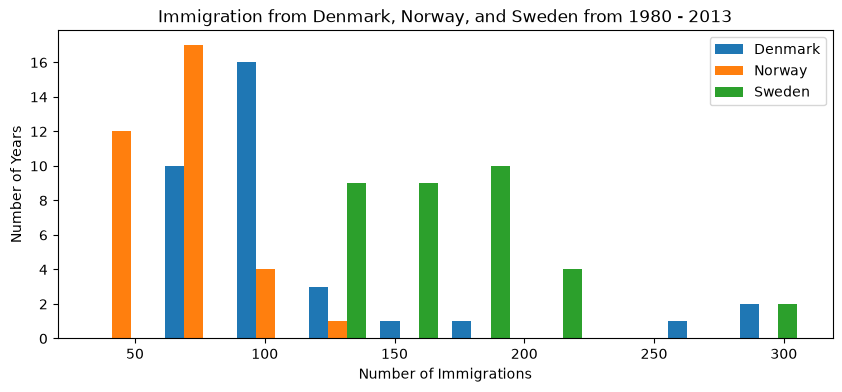

In [35]:
# Buat histogram
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_dns)
ax.set_title("Immigration from Denmark, Norway, and Sweden from 1980 - 2013")
ax.set_xlabel("Number of Immigrations")
ax.set_ylabel("Number of Years")
ax.legend(["Denmark", "Norway", "Sweden"])

# Tampilkan plot
plt.show()

### Pertanyaan: Bagaimana distribusi imigrasi untuk China dan India pada tahun 2000 hingga 2013?

In [36]:
years2 = list(map(str, range(2000, 2014)))

# Buat datafram khusus imigrasi China dan India
df_CI = df.loc[["China", "India"], years2]
df_CI = df_CI.T
df_CI.head()

Country,China,India
2000,35529,28572
2001,36434,31223
2002,31961,31889
2003,36439,27155
2004,36619,28235


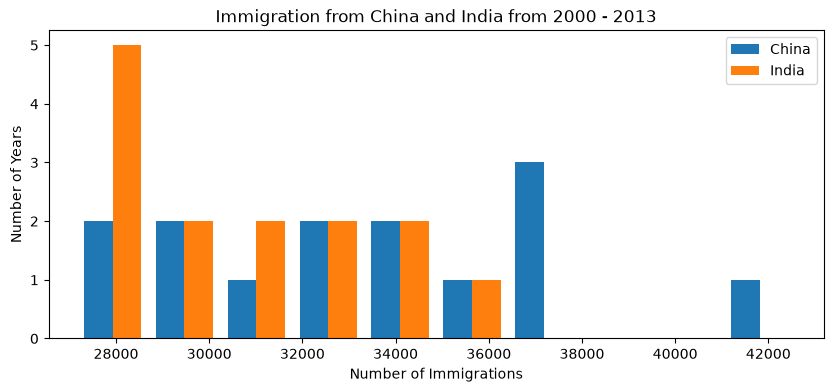

In [37]:
# Buat plot distribusi 
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_CI)
ax.set_title("Immigration from China and India from 2000 - 2013")
ax.set_xlabel("Number of Immigrations")
ax.set_ylabel("Number of Years")
ax.legend(["China", "India"])

# Tampilkan plot
plt.show()

# Pie Chart<a id="7"></a>

Diagram lingkaran (pie chart) mewakili proporsi atau persentase distribusi berbagai kategori dalam suatu kumpulan data menggunakan sektor-sektor lingkaran.
<br> Mari kita buat diagram lingkaran yang mewakili 'Jumlah Total Imigran' untuk tahun 1980 hingga 1985.

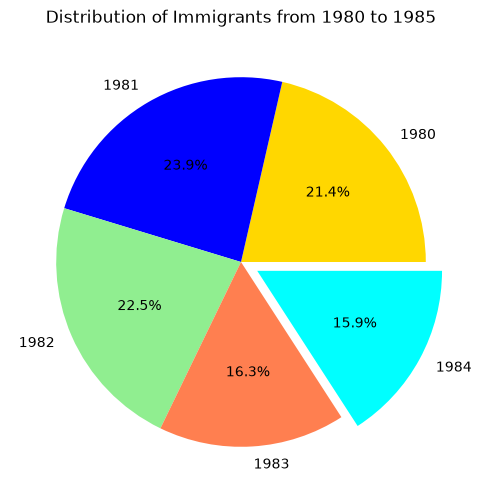

In [38]:
fig, ax = plt.subplots(figsize=(10, 6))

# Buat diagram pie
ax.pie(total_immigrants[0:5], labels=years[0:5],
      colors=["gold","blue","lightgreen","coral","cyan"],
      autopct="%1.1f%%", explode=[0, 0, 0, 0, 0.1]) # menggunakan fitur explode untuk menyoroti yang terendah.

# Pastikan pie diagram digambar berbentuk lingkaran.
ax.set_aspect("equal")

# Tambahkan judul
ax.set_title("Distribution of Immigrants from 1980 to 1985")

plt.show()

### Pertanyaan: Buatlah pie diagram yang mewakili proporsi total imigran untuk setiap benua

Pertama, Anda harus mengelompokkan data berdasarkan benua dan mendapatkan jumlah totalnya. Kemudian Anda dapat meneruskan data ini ke fungsi pie.

In [39]:
# Membuat data untuk membuat pie diagram
df_continents = df_canada.groupby("Continent")["Total"].sum().reset_index()
df_continents

,Continent,Total
0,Africa,618948
1,Asia,3317794
2,Europe,1410947
3,Latin America and the Caribbean,765148
4,Northern America,241142
5,Oceania,55174


In [40]:
# Buat label untuk continent (benua) saja
label_con = list(df_continents.Continent)
# Ubah label continent 3 dan 4 lebih pendek
label_con[3] = "Latin America"
label_con[4] = "North America"
label_con

['Africa', 'Asia', 'Europe', 'Latin America', 'North America', 'Oceania']

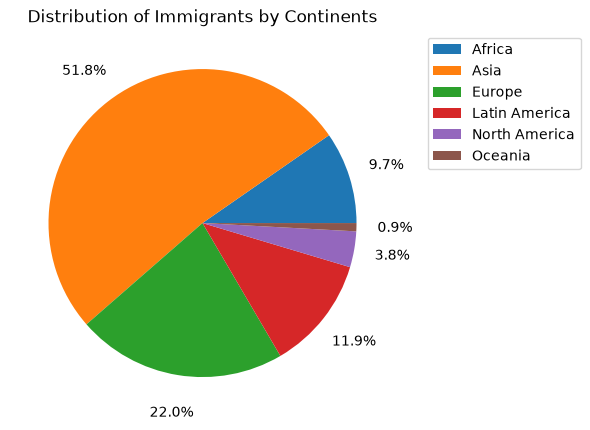

In [41]:
# Buat diagram pie
fig, ax = plt.subplots(figsize=(10, 5))

ax.pie(df_continents["Total"], autopct="%1.1f%%", pctdistance=1.25)
ax.set_aspect("equal")

ax.set_title("Distribution of Immigrants by Continents")
ax.legend(label_con, bbox_to_anchor=(1, 0, 0.5, 1))

plt.show()

# Sub-plotting<a id="8"></a>


Mari kita jelajahi cara menampilkan lebih dari satu plot pada gambar yang sama dan menentukan jumlah baris dan kolom yang akan dibuat pada fungsi subplots.

Misalnya, mari kita buat line plot dan scatter plot dalam satu baris <br>
plt.subplots() <br>
Anda dapat menggunakan fungsi yang sama yang Anda gunakan untuk membuat line plot dan scatter plot di awal lab ini
<br>
Kedua subplot akan berbagi sumbu y yang sama karena data pada sumbu y sama. Jadi, tetapkan parameter ‘Sharey’ sebagai True pada kode di bawah ini. Perhatikan juga penggunaan 'suptitle'

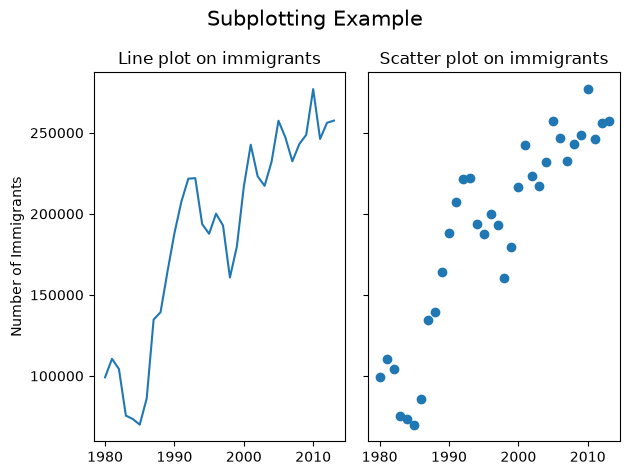

In [42]:
# Buatlah sebuah bangun dengan dua sumbu yang berjajar.
fig, axs = plt.subplots(1, 2, sharey=True)

# Memplot pada first axes - yang sebelah kiri
axs[0].plot(total_immigrants)
axs[0].set_title("Line plot on immigrants")

# Memplot pada second axes - yang sebelah kanan
axs[1].scatter(total_immigrants.index, total_immigrants)
axs[1].set_title("Scatter plot on immigrants")

axs[0].set_ylabel("Number of Immigrants")

# Menambahkan Judul untuk Gambar Keseluruhan
fig.suptitle("Subplotting Example", fontsize=15)

# Sesuaikan jarak antar subplot
fig.tight_layout()

# Tampilkan plot
plt.show()

Anda juga dapat menerapkan pembuatan subplot dengan **add_subplot()** seperti di bawah ini:

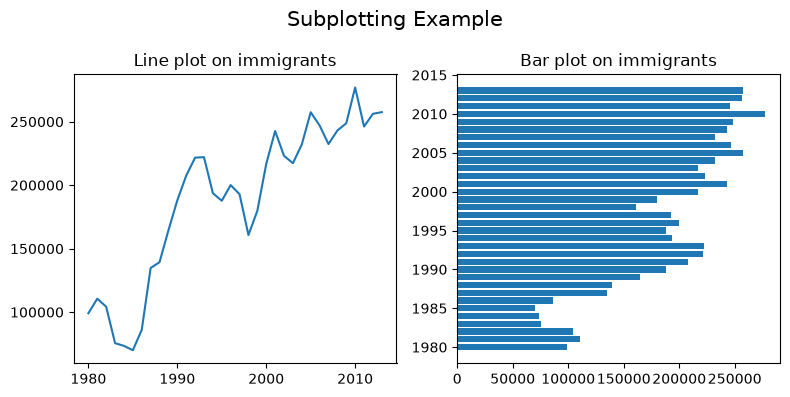

In [43]:
# Buatlah sebuah bangun dengan empat sumbu - dua baris, dua kolom
fig = plt.figure(figsize=(8,4))

# Tambahkan subplot pertama (kiri atas)
axs1 = fig.add_subplot(1, 2, 1)
# Plotting pada sumbu pertama - yang sebelah kiri
axs1.plot(total_immigrants)
axs1.set_title("Line plot on immigrants")

# Tambahkan subplot kedua (kanan atas)
axs2 = fig.add_subplot(1, 2, 2)
# Plotting pada sumbu kedua - yang sebelah kanan
axs2.barh(total_immigrants.index, total_immigrants) # Perhatikan penggunaan 'barh' untuk membuat plot batang horizontal.
axs2.set_title("Bar plot on immigrants")
            
# Menambahkan Judul untuk Gambar Keseluruhan
fig.suptitle('Subplotting Example', fontsize=15)

# Sesuaikan jarak antar subplot
fig.tight_layout()

# Tampilkan plot
plt.show()

### Pertanyaan: Pilih empat plot apa pun yang telah Anda buat dalam praktikum ini, dengan menampilkan subplot dalam tampilan 2x2.

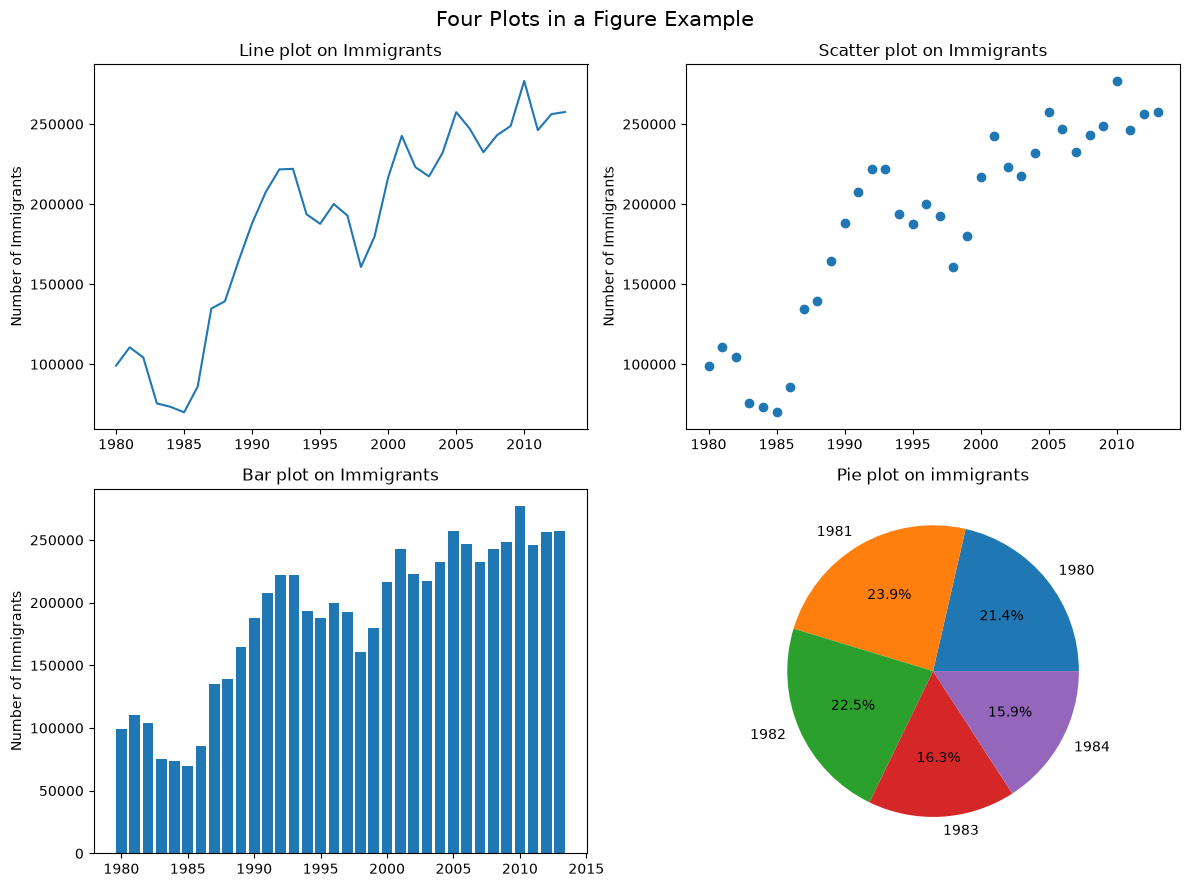

In [44]:
# Buat figures dengan empat axes - dua baris, dua kolom
fig, axs = plt.subplots(2, 2, figsize=(12, 9), sharey=False)

# Memplot pada first axes - yang sebelah kiri atas (line plot)
axs[0, 0].plot(total_immigrants)
axs[0, 0].set_title("Line plot on Immigrants")

# Memplot pada second axes - yang sebelah kanan atas (scatter plot)
axs[0, 1].scatter(total_immigrants.index, total_immigrants)
axs[0, 1].set_title("Scatter plot on Immigrants")

# Memplot pada third axes - yang sebelah kiri bawah (bar plot)
axs[1, 0].bar(total_immigrants.index, total_immigrants)
axs[1, 0].set_title("Bar plot on Immigrants")

# Memplot pada fourth axes - yang sebelah kanan bawah (pie plot)
axs[1, 1].pie(total_immigrants[0:5], labels=years[0:5],
          autopct="%1.1f%%")
axs[1, 1].set_aspect("equal")
axs[1, 1].set_title("Pie plot on immigrants")

# Label
axs[0, 0].set_ylabel("Number of Immigrants")
axs[0, 1].set_ylabel("Number of Immigrants")
axs[1, 0].set_ylabel("Number of Immigrants")

# Figure Title
fig.suptitle("Four Plots in a Figure Example", fontsize=15)
fig.tight_layout()

plt.show()